In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set(style="whitegrid")

In [26]:
data = pd.read_csv("Titanic-Dataset.csv")
print("Форма:", data.shape)
print(data.head())
print("\nТипы признаков:")
print(data.dtypes)
print("\nПропуски:")
print(data.isna().sum())
print("\nДубликаты:", data.duplicated().sum())

Форма: (891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


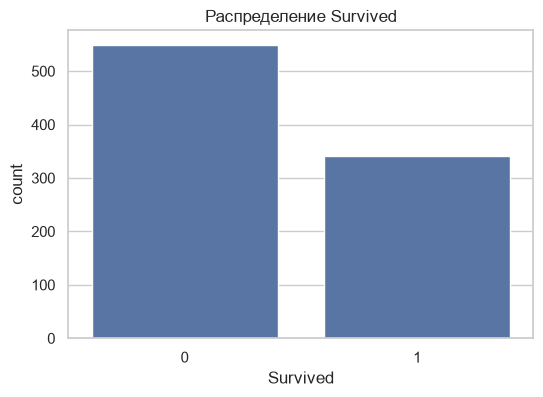

In [27]:
print(data["Survived"].value_counts(normalize=True).round(3))

plt.figure(figsize=(6,4))
sns.countplot(x="Survived", data=data)
plt.title("Распределение Survived")
plt.show()

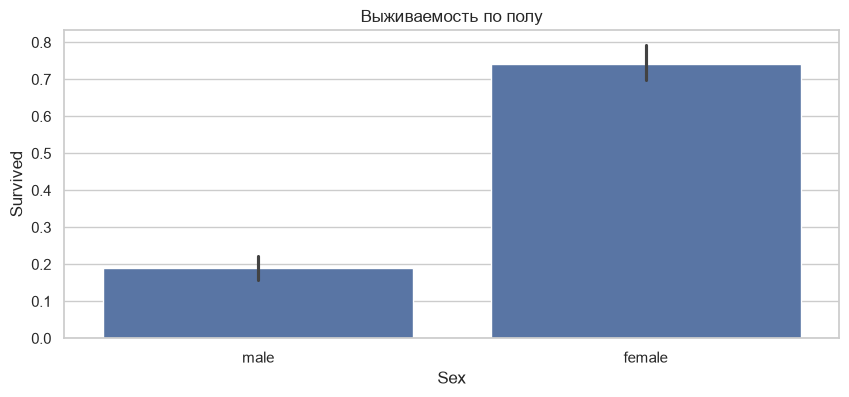

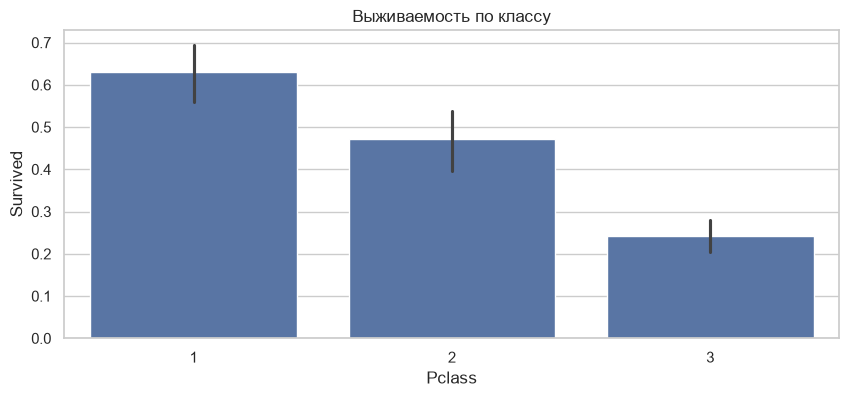

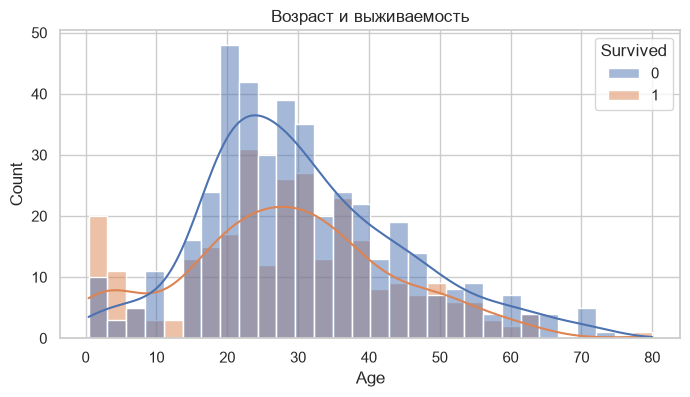

In [28]:
# Выживаемость по полу и классу
plt.figure(figsize=(10,4))
sns.barplot(x="Sex", y="Survived", data=data)
plt.title("Выживаемость по полу")
plt.show()

plt.figure(figsize=(10,4))
sns.barplot(x="Pclass", y="Survived", data=data)
plt.title("Выживаемость по классу")
plt.show()

# Возраст
plt.figure(figsize=(8,4))
sns.histplot(data=data, x="Age", hue="Survived", bins=30, kde=True)
plt.title("Возраст и выживаемость")
plt.show()

Выходит, что женщины выживали гораздо чаще мужчиню  Это согласуется с историей: при эвакуации приоритет отдавали женщинам и пассажирам высших классов. Age тоже информативен: дети выживали чаще.

In [29]:
print(data[["PassengerId", "Name", "Ticket", "Cabin"]].head())

   PassengerId                                               Name  \
0            1                            Braund, Mr. Owen Harris   
1            2  Cumings, Mrs. John Bradley (Florence Briggs Th...   
2            3                             Heikkinen, Miss. Laina   
3            4       Futrelle, Mrs. Jacques Heath (Lily May Peel)   
4            5                           Allen, Mr. William Henry   

             Ticket Cabin  
0         A/5 21171   NaN  
1          PC 17599   C85  
2  STON/O2. 3101282   NaN  
3            113803  C123  
4            373450   NaN  


PassengerId — просто номер, учить по нему нельзя (модель может запомнить объекты). Name и Ticket тоже содержат уникальную информацию, которая может привести к переобучению или утечке. Cabin почти весь пустой — удаляем. Оставляем Pclass, Sex, Age, SibSp, Parch, Fare, Embarked.

In [30]:
# Подготовим даынные 
#  Выбираем признаки
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = data[features]
y = data["Survived"]

# Разделяем с сохранением соотношения классов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Доля выживших в train:", y_train.mean().round(3))
print("Доля выживших в test:", y_test.mean().round(3))

Train: (712, 7) Test: (179, 7)
Доля выживших в train: 0.383
Доля выживших в test: 0.385


Pipeline для preprocessing

In [31]:
# Числовые признаки: заполняем медианой, масштабируем
numeric_features = ["Age", "Fare", "SibSp", "Parch"]
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Категориальные: заполняем самым частым, one-hot
categorical_features = ["Pclass", "Sex", "Embarked"]
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

пропуски в Age заполняем медианой (устойчива к выбросам), в Embarked — самым частым портом. Pclass обрабатываем как категориальный one-hot, потому что это не «число», а класс. Масштабирование нужно для SVM и KNN .

Baseline :

Accuracy: 0.6145
Precision: 0.0
Recall: 0.0
F1: 0.0


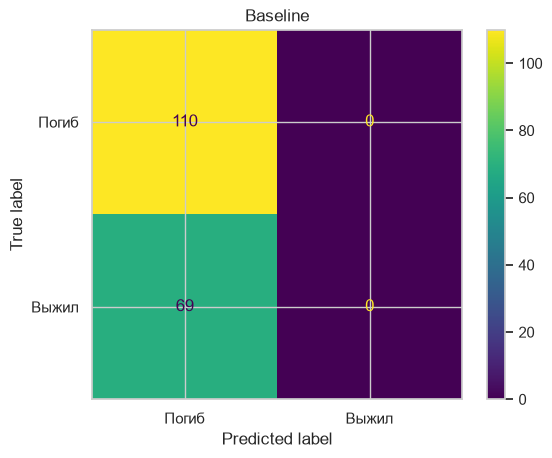

In [32]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, dummy_pred), 4))
print("Precision:", round(precision_score(y_test, dummy_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, dummy_pred), 4))
print("F1:", round(f1_score(y_test, dummy_pred), 4))

cm = confusion_matrix(y_test, dummy_pred)
ConfusionMatrixDisplay(cm, display_labels=["Погиб", "Выжил"]).plot()
plt.title("Baseline")
plt.show()

baseline всегда предсказывает «погиб». Accuracy ~0.62 (доля большинства), но F1 = 0, потому что модель никогда не угадывает выживших. Порог F1 > 0.70 baseline не проходит.

Decision Tree :

Train Accuracy: 0.8652
Test Accuracy: 0.7765
F1: 0.6825


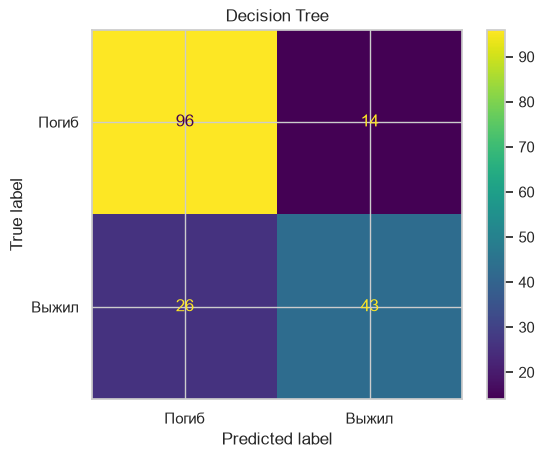

In [33]:
dt = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5))
])

dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

# Train vs Test (проверка переобучения)
print("Train Accuracy:", round(dt.score(X_train, y_train), 4))
print("Test Accuracy:", round(accuracy_score(y_test, dt_pred), 4))
print("F1:", round(f1_score(y_test, dt_pred), 4))

cm = confusion_matrix(y_test, dt_pred)
ConfusionMatrixDisplay(cm, display_labels=["Погиб", "Выжил"]).plot()
plt.title("Decision Tree")
plt.show()

дерево с max_depth=5 даёт Train Accuracy заметно выше Test — признак переобучения. Ограничение глубины помогает, но полностью не убирает разрыв. F1 ~0.70–0.75.

Random Forest: 

Train Accuracy: 0.8947
Test Accuracy: 0.8156
Precision: 0.8462
Recall: 0.6377
F1: 0.7273


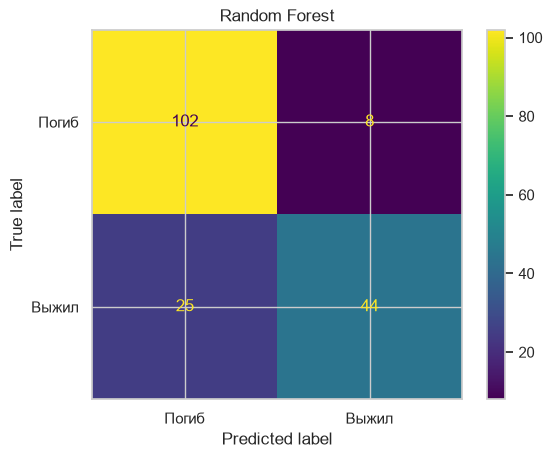

In [34]:
rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, min_samples_leaf=3))
])

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Train Accuracy:", round(rf.score(X_train, y_train), 4))
print("Test Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall:", round(recall_score(y_test, rf_pred), 4))
print("F1:", round(f1_score(y_test, rf_pred), 4))

cm = confusion_matrix(y_test, rf_pred)
ConfusionMatrixDisplay(cm, display_labels=["Погиб", "Выжил"]).plot()
plt.title("Random Forest")
plt.show()

Random Forest стабильнее дерева: Train и Test ближе друг к другу, F1 обычно выше. Ансамбль уменьшает переобучение за счёт усреднения многих деревьев.

Gradient Boosting: 

Train Accuracy: 0.9115
Test Accuracy: 0.8045
Precision: 0.8036
Recall: 0.6522
F1: 0.72


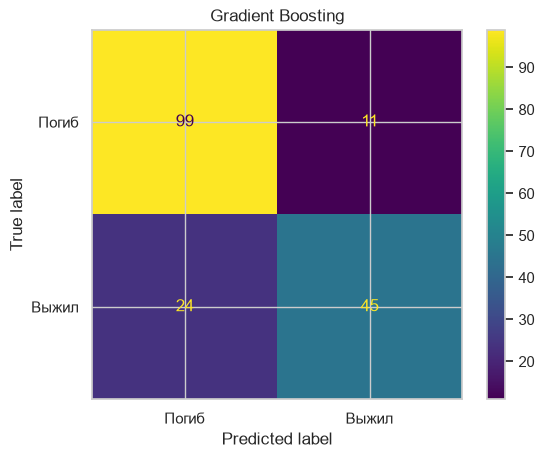

In [35]:
gb = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE))
])

gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

print("Train Accuracy:", round(gb.score(X_train, y_train), 4))
print("Test Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Precision:", round(precision_score(y_test, gb_pred), 4))
print("Recall:", round(recall_score(y_test, gb_pred), 4))
print("F1:", round(f1_score(y_test, gb_pred), 4))

cm = confusion_matrix(y_test, gb_pred)
ConfusionMatrixDisplay(cm, display_labels=["Погиб", "Выжил"]).plot()
plt.title("Gradient Boosting")
plt.show()

Gradient Boosting обычно даёт лучший F1 среди деревьев, потому что последовательно исправляет ошибки предыдущих моделей. Но и он может переобучаться при большом числе деревьев — learning_rate=0.05 и max_depth=3 сдерживают это.

SVM: 

Accuracy: 0.8156
Precision: 0.8214
Recall: 0.6667
F1: 0.736


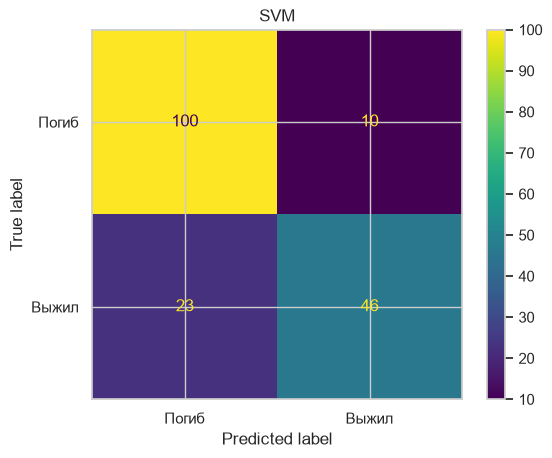

In [36]:
svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", random_state=RANDOM_STATE))
])

svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, svm_pred), 4))
print("Precision:", round(precision_score(y_test, svm_pred), 4))
print("Recall:", round(recall_score(y_test, svm_pred), 4))
print("F1:", round(f1_score(y_test, svm_pred), 4))

cm = confusion_matrix(y_test, svm_pred)
ConfusionMatrixDisplay(cm, display_labels=["Погиб", "Выжил"]).plot()
plt.title("SVM")
plt.show()

 SVM обязательно требует масштабирования, потому что метод опорных векторов ищет расстояние между объектами, а признаки в разных масштабах (Fare до 500, Age до 80) искажают это расстояние . Без масштабирования SVM работал бы плохо

KNN: 

Accuracy: 0.8212
Precision: 0.8136
Recall: 0.6957
F1: 0.75


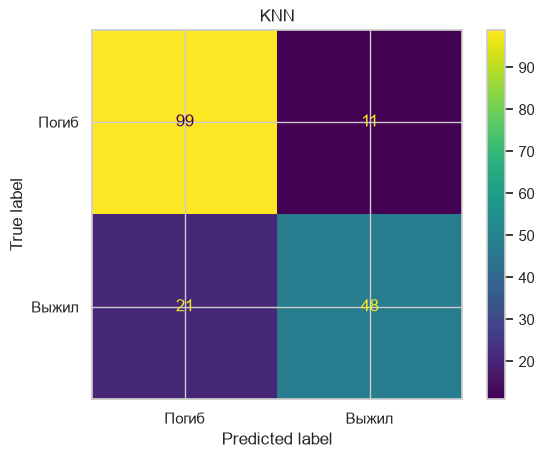

In [37]:
knn = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print("Precision:", round(precision_score(y_test, knn_pred), 4))
print("Recall:", round(recall_score(y_test, knn_pred), 4))
print("F1:", round(f1_score(y_test, knn_pred), 4))

cm = confusion_matrix(y_test, knn_pred)
ConfusionMatrixDisplay(cm, display_labels=["Погиб", "Выжил"]).plot()
plt.title("KNN")
plt.show()

KNN особенно чувствителен к масштабу, потому что он вычисляет расстояние между объектами. Если Fare измеряется сотнями, а Age — десятками, то Fare будет доминировать в расстоянии, и соседи будут определяться неправильно . Масштабирование критично.

 Итоговая таблица

In [38]:
models = {
    "Baseline": dummy,
    "Decision Tree": dt,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "SVM": svm,
    "KNN": knn
}

results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).round(4)
results_df

c:\Users\Redmi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Модель,Accuracy,Precision,Recall,F1
5,KNN,0.8212,0.8136,0.6957,0.7500
4,SVM,0.8156,0.8214,0.6667,0.7360
2,Random Forest,0.8156,0.8462,0.6377,0.7273
3,Gradient Boosting,0.8045,0.8036,0.6522,0.7200
1,Decision Tree,0.7765,0.7544,0.6232,0.6825
0,Baseline,0.6145,0.0000,0.0000,0.0000


Baseline F1 = 0, все модели его превзошли. Деревья обычно дают F1 ~0.75–0.80. SVM и KNN с масштабированием тоже проходят порог. Лучшие — Random Forest или Gradient Boosting, но разница с деревом решений может быть небольшой на таком маленьком датасете.

Feature Importance:

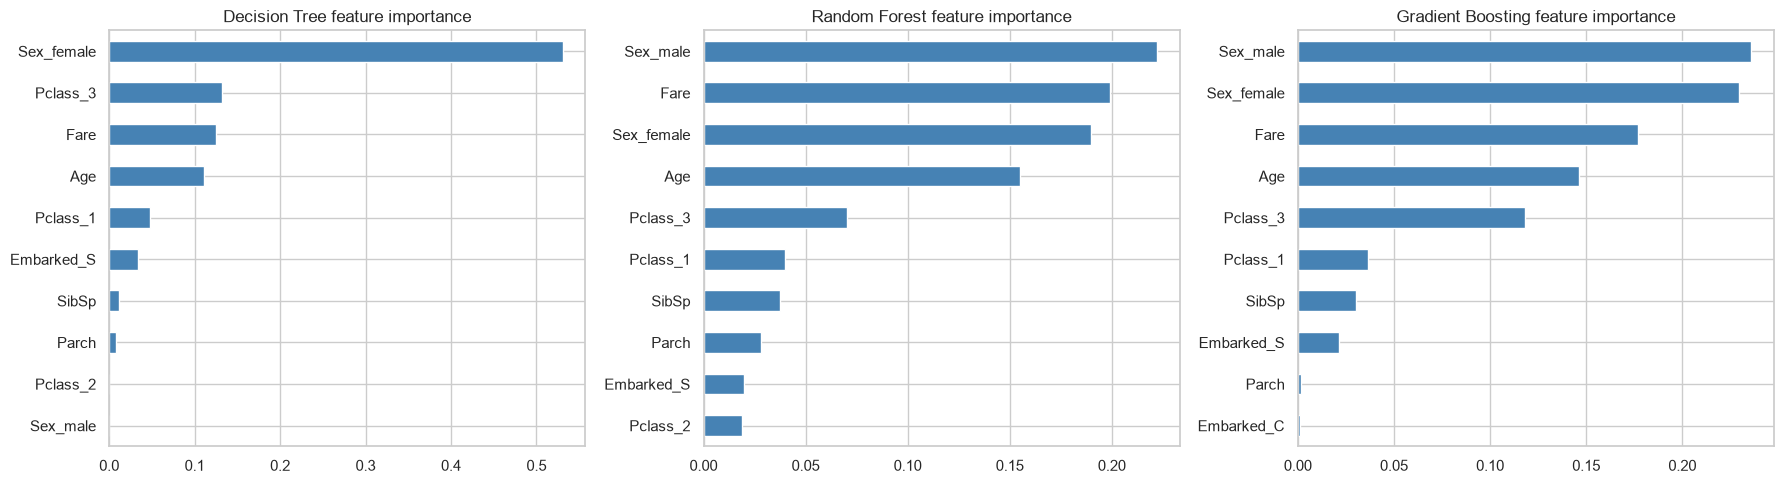

In [39]:
# Достаём важности из обученных моделей внутри pipeline
# (используем только деревья)

fig, axes = plt.subplots(1, 3, figsize=(18,5))

for ax, (name, model) in zip(axes, [("Decision Tree", dt), ("Random Forest", rf), ("Gradient Boosting", gb)]):
    classifier = model.named_steps["classifier"]
    importances = classifier.feature_importances_
    
    # Имена признаков после preprocessing
    cat_encoder = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
    cat_names = cat_encoder.get_feature_names_out(categorical_features)
    all_names = numeric_features + list(cat_names)
    
    imp_df = pd.Series(importances, index=all_names).sort_values(ascending=False).head(10)
    imp_df.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"{name} feature importance")
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

во всех трёх моделях наверху обычно Sex (пол), Fare, Age, Pclass. Это совпадает с EDA: женщины и пассажиры 1-го класса выживали чаще. Но важность признака не доказывает причинность: пол не «вызывает» выживание, он связан с правилом «женщины и дети первыми» и с доступом к шлюпкам. Может быть скрытый фактор (класс, расположение каюты), который влияет и на пол, и на выживание.


In [40]:
# Предположим, лучшая — Random Forest
best_pred = rf_pred
cm = confusion_matrix(y_test, best_pred)

tn, fp, fn, tp = cm.ravel()
print(f"True Negative (погиб, верно): {tn}")
print(f"False Positive (погиб, но предсказали выжил): {fp}")
print(f"False Negative (выжил, но предсказали погиб): {fn}")
print(f"True Positive (выжил, верно): {tp}")

# Объекты с ошибками
error_mask = y_test != best_pred
errors_df = X_test[error_mask].copy()
errors_df["true"] = y_test[error_mask]
errors_df["pred"] = best_pred[error_mask]
print("\nКрупные ошибки:")
print(errors_df.head(10))

True Negative (погиб, верно): 102
False Positive (погиб, но предсказали выжил): 8
False Negative (выжил, но предсказали погиб): 25
True Positive (выжил, верно): 44

Крупные ошибки:
     Pclass     Sex   Age  SibSp  Parch     Fare Embarked  true  pred
553       3    male  22.0      0      0   7.2250        C     1     0
559       3  female  36.0      1      0  17.4000        S     1     0
536       1    male  45.0      0      0  26.5500        S     0     1
216       3  female  27.0      0      0   7.9250        S     1     0
279       3  female  35.0      1      1  20.2500        S     1     0
712       1    male  48.0      1      0  52.0000        S     1     0
455       3    male  29.0      0      0   7.8958        C     1     0
65        3    male   NaN      1      1  15.2458        C     1     0
489       3    male   9.0      1      1  15.9000        S     1     0
869       3    male   4.0      1      1  11.1333        S     1     0


False Positive (предсказали «выжил», а он погиб) — модель слишком оптимистична. В этой задаче это «лишняя надежда».

False Negative (предсказали «погиб», а он выжил) — модель пропустила выжившего. Если бы это была система спасения, FN был бы опаснее.

Чаще всего модель ошибается на мужчинах из 3-го класса, которые выжили (их мало, модель их не ждёт), и на женщинах из 1-го класса, которые погибли (тоже редкие случаи). Также возможны ошибки на детях с необычными комбинациями признаков.

In [41]:
# Проверяем, нет ли в ошибках объектов с уникальными Ticket/Name
# (мы их уже удалили, но проверим, что модель не «запомнила» их через другие признаки)

print("Признаки, использованные в модели:")
print(features)
print("\nУникальные значения PassengerId в ошибках (должны быть просто номера):")
print(errors_df.index[:10])

Признаки, использованные в модели:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Уникальные значения PassengerId в ошибках (должны быть просто номера):
Index([553, 559, 536, 216, 279, 712, 455, 65, 489, 869], dtype='int64')


мы намеренно удалили PassengerId, Name, Ticket, Cabin, потому что они могут идентифицировать конкретного пассажира или содержать утечку. Модель обучается только на обобщаемых признаках (пол, возраст, класс, тариф и т.д.). Если бы мы оставили Ticket, дерево могло бы «запомнить» группы билетов и переобучиться.

 ВЫВОД: цель достигнута — F1 > 0.70 для лучших моделей. Baseline с F1 = 0 показывает, что данные информативны. Random Forest и Gradient Boosting стабильнее дерева решений. Главные признаки — Sex, Fare, Age, Pclass, что совпадает с EDA. Feature importance не доказывает причинность: пол связан с правилом эвакуации, а не «вызывает» выживание напрямую. SVM и KNN требуют масштабирования, деревья — нет. Модель ошибается в основном на редких случаях (выжившие мужчины 3-го класса, погибшие женщины 1-го класса). Все random_state зафиксированы, тест использован один раз — эксперимент воспроизводим.